In [1]:
import ROOT as r
import uproot
from matplotlib import pyplot as plt
import numpy as np
from scipy.stats import ks_2samp, chi2 as chi2_dist

import sys
sys.path.insert(0, '/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/')
import os; os.environ['MEDULLA_PLOT_DIR'] = '/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/'

import matplotlib.pyplot as plt
from style import stamp

plt.style.use('/nashome/m/micarrig/icarus/nuESpine/medulla/spineplot/styles/nue2024.mplstyle')

In [2]:
fin = uproot.open('/exp/icarus/data/users/micarrig/merged_v30.root')

In [3]:
e_bins = [300, 390, 490, 600, 730, 870, 1030, 1240, 1500, 2000, 5000]

In [17]:
ppfx = fin['events/NuMIFull/selected/ppfx_cv_weight'].array(library='np')
ele_e = fin['events/NuMIFull/selected/reco_leading_electron_energy'].array(library='np')
theta_delta2Npi = fin['events/NuMIFull/selected_multisigmaTree/Theta_Delta2Npi'].array(library='np')

theta_delta2Npi = np.array([x[0] for x in theta_delta2Npi])

In [18]:
theta_delta2Npi[0]

np.float64(1.0)

<>:17: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
<>:17: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
/tmp/ipykernel_1996/3909812787.py:17: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  ax[0].text(0.95, 0.75, f'$\chi^2/ndof$ = {chi2_val:.2f}/{ndof} = {chi2_val/ndof:.2f} \np-value = {p_chi2:.3f}', transform=ax[0].transAxes, ha='right', va='top', fontsize=16)


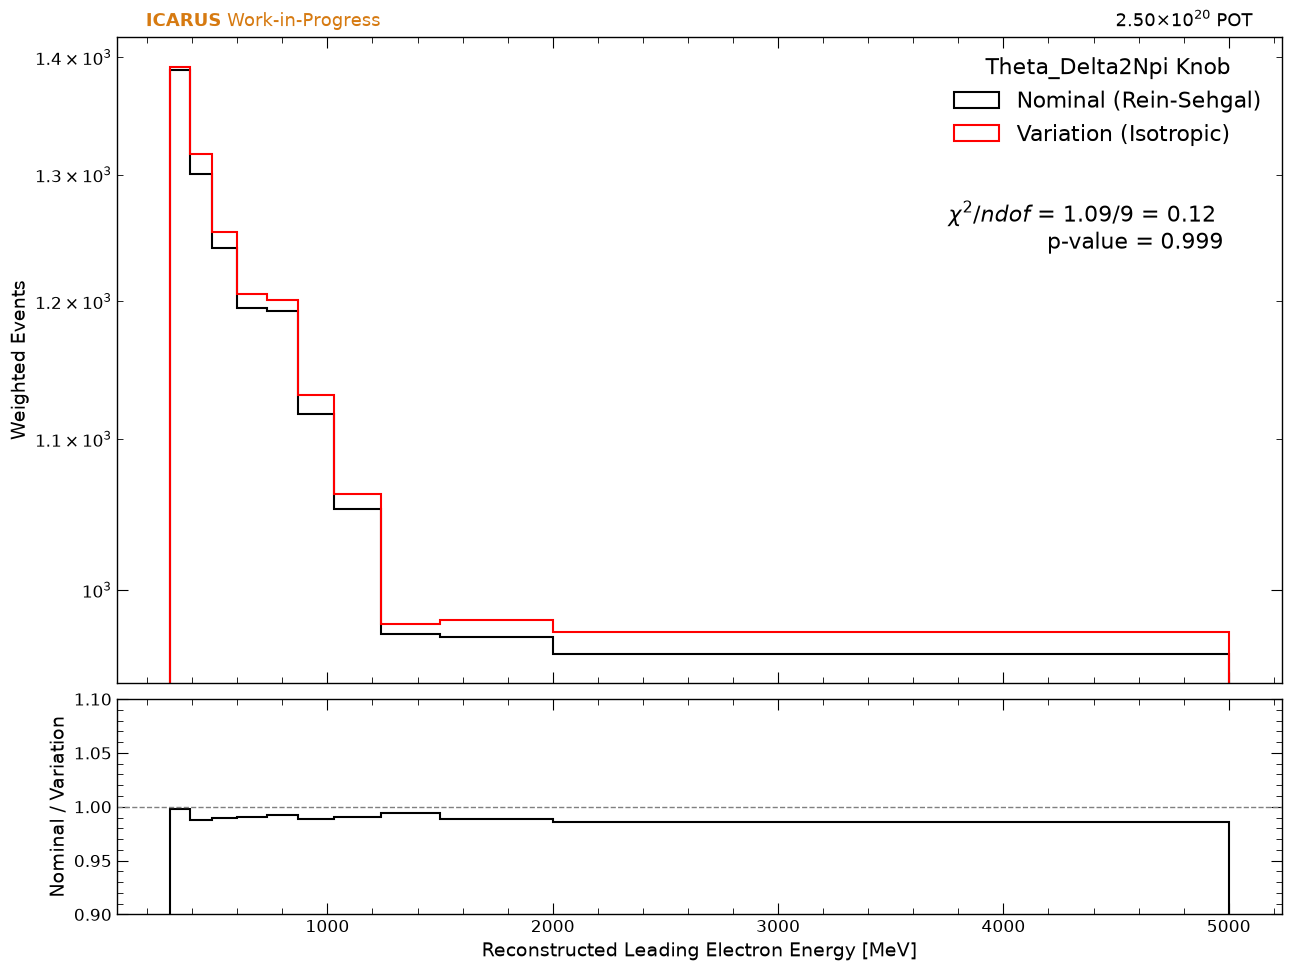

In [37]:
fig, ax = plt.subplots(2, 1, figsize=(12.8, 9.6), gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

ax[0].hist(ele_e, bins=e_bins, weights=ppfx, histtype='step', color='black', label='Nominal (Rein-Sehgal)', linewidth=1.5)
ax[0].hist(ele_e, bins=e_bins, weights=ppfx * theta_delta2Npi, histtype='step', color='red', label=r'Variation (Isotropic)', linewidth=1.5)

ax[0].set_ylabel('Weighted Events')
ax[0].set_yscale('log')
ax[0].legend(title='Theta_Delta2Npi Knob', fontsize=16, title_fontsize=16, loc='upper right')

cv = np.histogram(ele_e, bins=e_bins, weights=ppfx)[0]
sys = np.histogram(ele_e, bins=e_bins, weights=ppfx * theta_delta2Npi)[0]

ndof = len(cv) - 1
chi2_val = float(np.sum((sys - cv)**2 / cv))
p_chi2 = float(chi2_dist.sf(chi2_val, ndof))

ax[0].text(0.95, 0.75, f'$\chi^2/ndof$ = {chi2_val:.2f}/{ndof} = {chi2_val/ndof:.2f} \np-value = {p_chi2:.3f}', transform=ax[0].transAxes, ha='right', va='top', fontsize=16)

ratio = np.divide(cv, sys, out=np.full(len(cv), np.nan), where=sys > 0)
ax[1].stairs(ratio, e_bins, color='black', linewidth=1.5)
ax[1].axhline(1, color='gray', linestyle='--', linewidth=1)
ax[1].set_xlabel('Reconstructed Leading Electron Energy [MeV]')
ax[1].set_ylabel(r'Nominal / Variation')
ax[1].set_ylim(0.9, 1.1)

stamp(ax[0], pot=2.5e20, work_in_progress=True)

plt.show()